In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
df = pd.read_csv('../results/csv/ite_tree_results_[0, 1, 2, 3, 4]_5000.csv')
df.head()

,h,alpha,pr_satisfiable,avg_runtime
0,0,0.000000,0.4968,0.000001
1,0,0.010013,0.5080,0.000001
2,0,0.020025,0.5004,0.000001
3,0,0.030038,0.5008,0.000001
4,0,0.040050,0.5032,0.000001


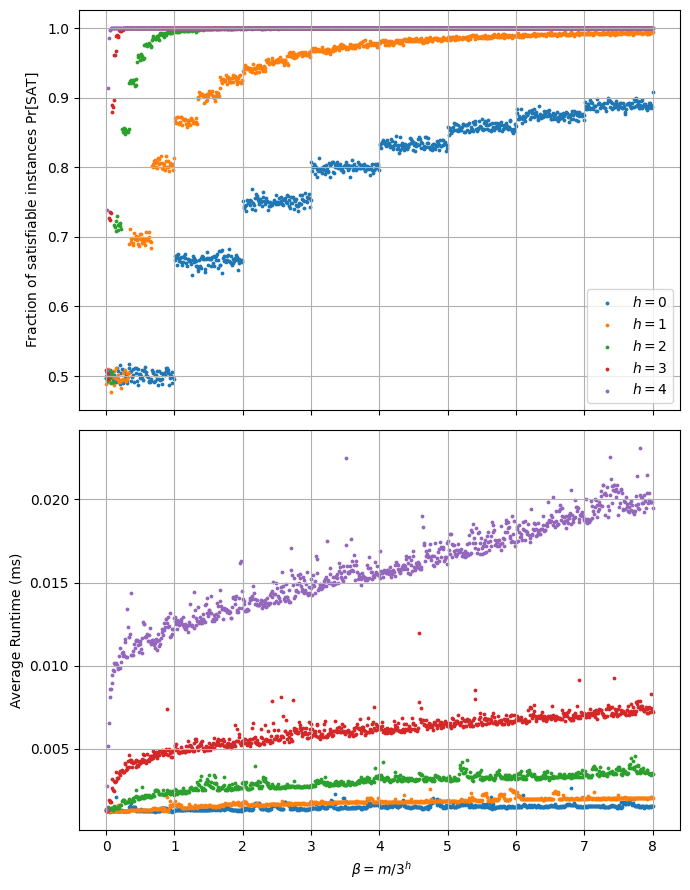

In [60]:
# for n in df['h'].unique():
#     subset = df[df['h'] == n]
#     plt.plot(subset['alpha'], subset['pr_satisfiable'], label=f'h={n}')
#     # plt.scatter(subset['alpha'], subset['pr_satisfiable'], label=f'h={n}', s=1)
# plt.xlabel(r" $\beta = m/3^h$")
# plt.ylabel(r"Fraction of satisfiable instances $\Pr[\rm SAT]$")
# # plt.title('Phase Transition in ITE')
# plt.legend()
# plt.grid()
# plt.tight_layout()
# plt.show()


fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(7, 9))

crossing_points = []

for h in sorted(df['h'].unique()):
    subset = df[df['h'] == h]
    x = subset['alpha'].values
    y_prob = subset['pr_satisfiable'].values
    y_time = subset['avg_runtime'].values * 1000  # Convert to ms
    
    # Plot Probability on top (ax1)
    ax1.scatter(x, y_prob, label=fr"$h={h}$", s=3)
    
    # Plot Runtime on bottom (ax2)
    ax2.scatter(x, y_time, label=fr"$h={h}$", s=3)
    

# Formatting Top Plot (Probability)
ax1.set_ylabel(r"Fraction of satisfiable instances $\Pr[\rm SAT]$")
ax1.grid(True)
ax1.legend()

# Formatting Bottom Plot (Runtime)
ax2.set_ylabel(r"Average Runtime (ms)")
ax2.set_xlabel(r" $\beta = m/3^h$")
ax2.grid(True)

plt.tight_layout()
plt.show()

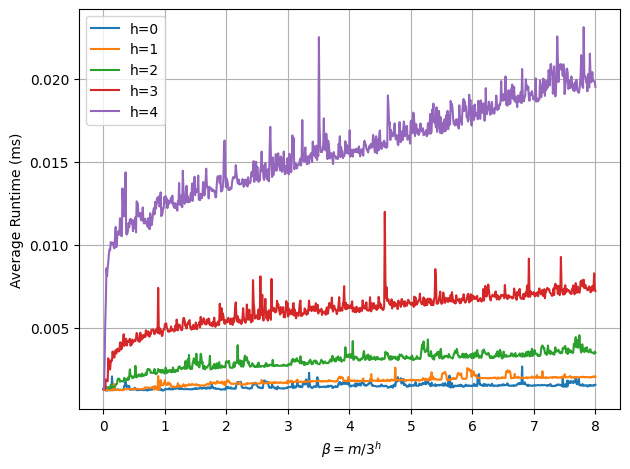

In [49]:
df['avg_runtime_ms'] = df['avg_runtime'] * 1000

for n in df['h'].unique():
    subset = df[df['h'] == n]
    plt.plot(subset['alpha'], subset['avg_runtime_ms'], label=f'h={n}')
# plt.yscale('log')
plt.xlabel(r" $\beta = m/3^h$")
plt.ylabel('Average Runtime (ms)')
# plt.title('Solver Runtime vs Clause Density')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

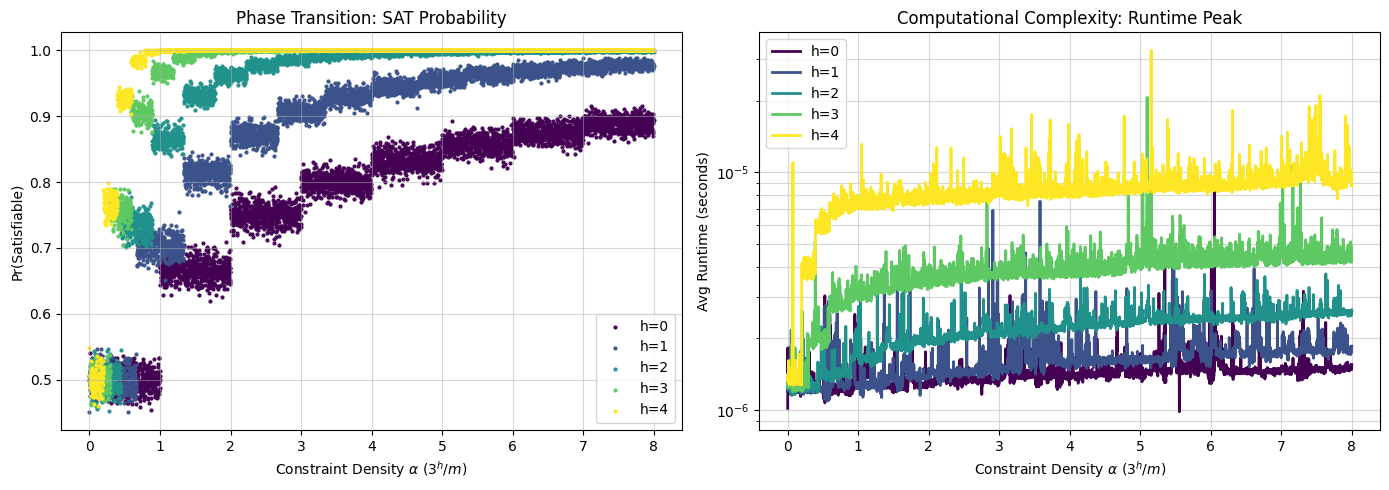

In [5]:
def plot_results(df):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    # Use a distinct color map for the different tree depths
    colors = plt.cm.viridis(np.linspace(0, 1, len(df['h'].unique())))

    for i, h_val in enumerate(sorted(df['h'].unique())):
        subset = df[df['h'] == h_val]
        
        # 1. Probability Plot
        ax1.scatter(subset['alpha'], subset['pr_satisfiable'], 
                 label=f'h={h_val}', color=colors[i], linewidth=2, s=1)
        
        # 2. Runtime Plot
        ax2.plot(subset['alpha'], subset['avg_runtime'], 
                 label=f'h={h_val}', color=colors[i], linewidth=2)

    # Styling the Probability Plot
    ax1.set_xlabel(r'Constraint Density $\alpha$ ($3^h / m$)')
    ax1.set_ylabel('Pr(Satisfiable)')
    ax1.set_title('Phase Transition: SAT Probability')
    ax1.grid(True, which="both", ls="-", alpha=0.5)
    ax1.legend()

    # Styling the Runtime Plot
    ax2.set_xlabel(r'Constraint Density $\alpha$ ($3^h / m$)')
    ax2.set_ylabel('Avg Runtime (seconds)')
    ax2.set_yscale('log') # CRITICAL: Shows exponential growth clearly
    ax2.set_title('Computational Complexity: Runtime Peak')
    ax2.grid(True, which="both", ls="-", alpha=0.5)
    ax2.legend()

    plt.tight_layout()
    plt.show()

plot_results(df)


In [40]:
df = pd.read_csv('../results/ite_tree_results_[10, 50, 100, 200]_1000.csv')
df.head()

,m,alpha,pr_satisfiable,avg_runtime
0,10,0.000000,0.907,0.000001
1,10,0.160032,1.000,0.000004
2,10,0.320064,1.000,0.000004
3,10,0.480096,0.995,0.000002
4,10,0.640128,0.998,0.000002


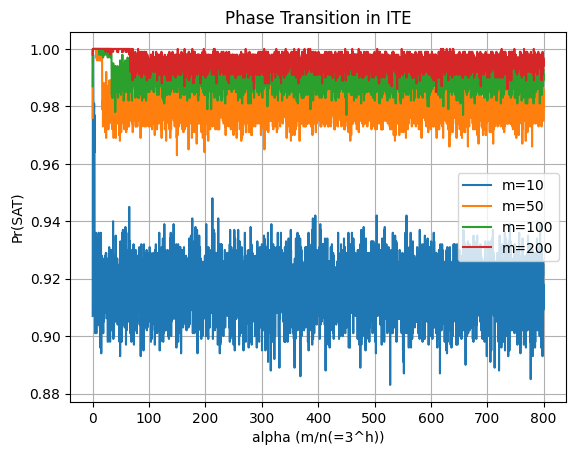

In [41]:
# # for n in df['h'].unique():
# #     subset = df[df['h'] == n]
# #     plt.plot(subset['alpha'], subset['pr_satisfiable'], label=f'h={n}')
# # plt.xlabel('alpha (m/n(=3^h))')
# # plt.ylabel('Pr(SAT)')
# # plt.title('Phase Transition in ITE')
# # plt.legend()
# # plt.grid()
# # plt.show()

# # plot of pr_satisfiable vs h, only one alpha = m = 3 in the csv
# # subset = df[df['m'] == 3]
# plt.plot(df['p_const'], df['pr_satisfiable'], marker='o')
# plt.xlabel('p_const')
# plt.ylabel('Pr(SAT)')
# plt.title('Pr(SAT) vs p_const for m=3')
# plt.grid()
# plt.show()

for n in df['m'].unique():
    subset = df[df['m'] == n]
    plt.plot(subset['alpha'], subset['pr_satisfiable'], label=f'm={n}')
    # plt.scatter(subset['alpha'], subset['pr_satisfiable'], label=f'm={n}', s=1)
plt.xlabel('alpha (m/n(=3^h))')
plt.ylabel('Pr(SAT)')
plt.title('Phase Transition in ITE')
plt.legend()
plt.grid()
plt.show()

In [35]:
df = pd.read_csv('../results/ite_tree_results_5_1000_mlog.csv')
df.head()

,h,alpha,pr_satisfiable,avg_runtime
0,1,0,0.510,0.000001
1,2,0,0.490,0.000001
2,3,0,0.514,0.000001
3,4,0,0.487,0.000001
4,5,0,0.492,0.000004


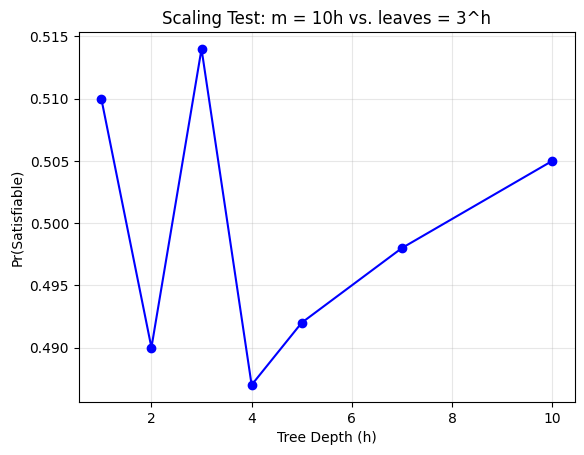

In [36]:
# Plotting logic for Experiment 1
plt.plot(df['h'], df['pr_satisfiable'], marker='o', linestyle='-', color='b')
plt.xlabel('Tree Depth (h)')
plt.ylabel('Pr(Satisfiable)')
plt.title('Scaling Test: m = 10h vs. leaves = 3^h')
plt.grid(True, alpha=0.3)
plt.show()




In [52]:
df = pd.read_csv('../results/ite_contingency_test_100_1000.csv')
df.head()

,h,pr_contingent,pr_tautology,pr_unsat,pr_sat_total
0,1,1.0,0.0,0.0,1.0
1,2,1.0,0.0,0.0,1.0
2,3,1.0,0.0,0.0,1.0
3,4,1.0,0.0,0.0,1.0
4,5,1.0,0.0,0.0,1.0


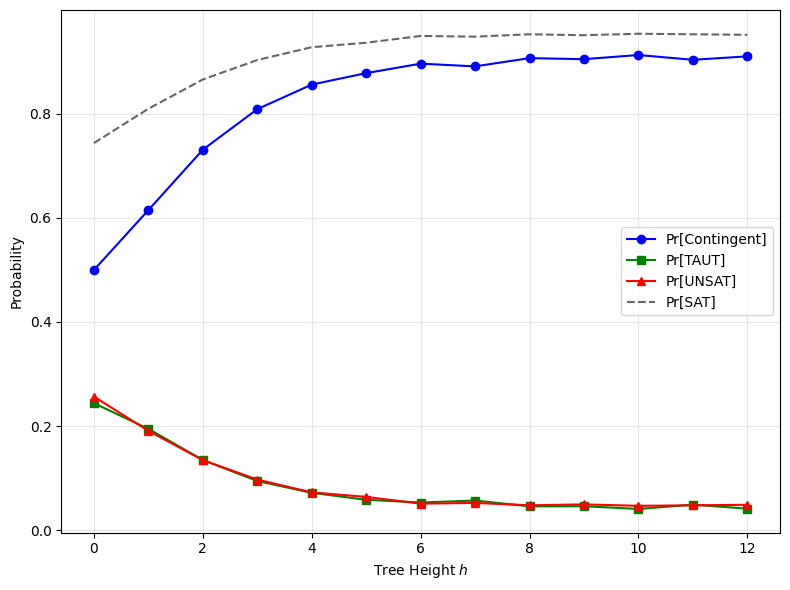

In [105]:
def plot_contingency(csv_file):
    df = pd.read_csv(csv_file)
    
    plt.figure(figsize=(8, 6))
    
    # 1. Contingent: Variables can change the outcome
    plt.plot(df['h'], df['pr_contingent'], label='Pr[Contingent]', marker='o', color='blue')
    
    # 2. Tautology: Forced True by structure
    plt.plot(df['h'], df['pr_tautology'], label='Pr[TAUT]', marker='s', color='green')
    
    # 3. UNSAT: Forced False by structure
    plt.plot(df['h'], df['pr_unsat'], label='Pr[UNSAT]', marker='^', color='red')
    
    # 4. Total Satisfiability (what you saw before)
    plt.plot(df['h'], df['pr_sat_total'], label='Pr[SAT]', linestyle='--', color='black', alpha=0.6)

    plt.xlabel(r"Tree Height $h$")
    plt.ylabel("Probability")
    # plt.title('The Decay of Contingency as Depth Increases')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_contingency("../results/csv/ite_contingency_optimized_2_noneg.csv")

# df1 = pd.read_csv('../results/csv/ite_contingency_ooptimized_1.csv')
# df2 = pd.read_csv('../results/csv/ite_contingency_ooptimized_1_noneg.csv')

# # Create a figure with 2 stacked subplots sharing the X-axis
# fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(7, 9))

# ax1.plot(df1['h'], df1['pr_contingent'], label='Pr[Contingent]', marker='o', color='blue')
# ax1.plot(df1['h'], df1['pr_tautology'], label='Pr[TAUT]', marker='s', color='green')
# ax1.plot(df1['h'], df1['pr_unsat'], label='Pr[UNSAT]', marker='^', color='red')
# ax1.plot(df1['h'], df1['pr_sat_total'], label='Pr[SAT]', linestyle='--', color='black', alpha=0.6)

# ax2.plot(df2['h'], df2['pr_contingent'], label='Pr[Contingent]', marker='o', color='blue')
# ax2.plot(df2['h'], df2['pr_tautology'], label='Pr[TAUT]', marker='s', color='green')
# ax2.plot(df2['h'], df2['pr_unsat'], label='Pr[UNSAT]', marker='^', color='red')
# ax2.plot(df2['h'], df2['pr_sat_total'], label='Pr[SAT]', linestyle='--', color='black', alpha=0.6)

# # Formatting Top Plot (Probability)
# ax1.set_ylabel("Probability")
# ax1.grid(True)

# # Formatting Bottom Plot (Runtime)
# ax2.set_ylabel("Probability")
# ax2.set_xlabel(r"Tree Height $h$")
# ax2.grid(True)

# plt.tight_layout()
# plt.show()


Plot successfully saved as 'lambda_plots.png'


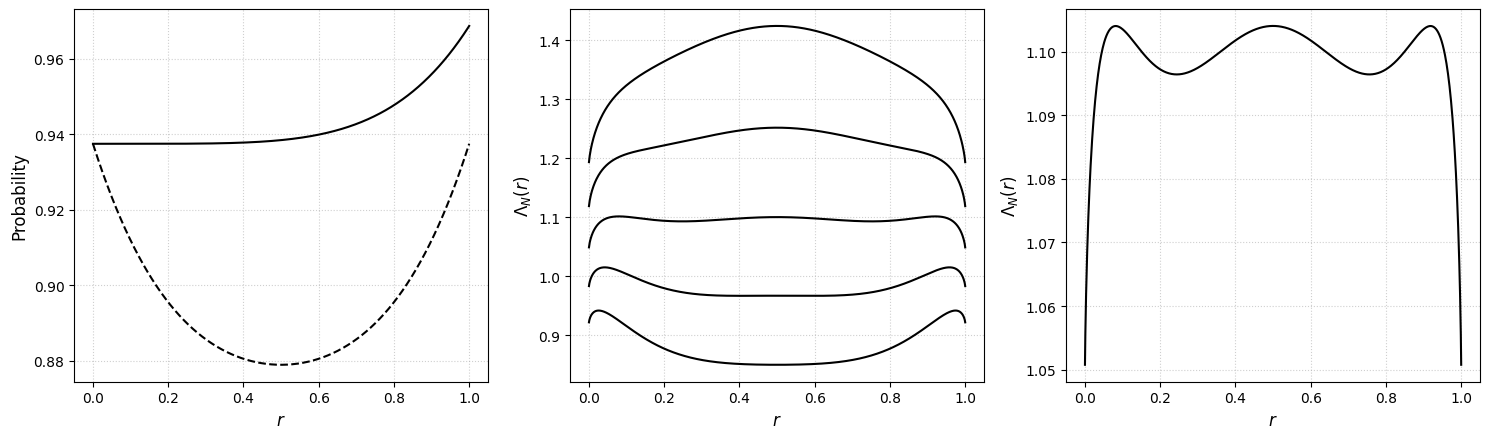

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Set up the parameters
k = 5
# Use a tiny epsilon to avoid 0^0 mathematical warnings, though limit is 1
eps = 1e-10
r = np.linspace(eps, 1-eps, 1000)

# Define the functions based on your thesis equations
def f_S(r_val):
    return 1 - 2**(1-k) + (2**(-k)) * (r_val**k)

def f_N(r_val):
    return 1 - 2**(2-k) + (2**(1-k)) * (r_val**k + (1-r_val)**k)

def Lambda_N(r_val, alpha):
    denom = (r_val**r_val) * ((1-r_val)**(1-r_val))
    return (2 * (f_N(r_val)**alpha)) / denom

# Create a 1x3 subplot layout
fig, axs = plt.subplots(1, 3, figsize=(15, 4.5))

# --- Left Plot: f_S vs f_N ---
axs[0].plot(r, f_S(r), 'k-', label=r'$f_S(r)$')
axs[0].plot(r, f_N(r), 'k--', label=r'$f_N(r)$')
axs[0].set_xlabel('$r$', fontsize=12)
axs[0].set_ylabel('Probability', fontsize=12)
# axs[0].set_title('Correlation Functions', fontsize=14)
axs[0].grid(True, linestyle=':', alpha=0.6)
# axs[0].legend(fontsize=12)

# --- Middle Plot: Lambda_N for different alphas ---
alphas = [8, 9, 10, 11, 12]
for alpha in alphas:
    axs[1].plot(r, Lambda_N(r, alpha), color='black', label=rf'$\alpha={alpha}$')
axs[1].set_xlabel('$r$', fontsize=12)
axs[1].set_ylabel(r'$\Lambda_N(r)$', fontsize=12)
# axs[1].set_title(r'$\Lambda_N$ for varying $\alpha$', fontsize=14)
axs[1].grid(True, linestyle=':', alpha=0.6)
# axs[1].legend(fontsize=11)

# --- Right Plot: Lambda_N at alpha = 9.973 ---
axs[2].plot(r, Lambda_N(r, 9.973), 'k-')
axs[2].set_xlabel('$r$', fontsize=12)
axs[2].set_ylabel(r'$\Lambda_N(r)$', fontsize=12)
# axs[2].set_title(r'Critical density $\alpha = 9.973$', fontsize=14)
axs[2].grid(True, linestyle=':', alpha=0.6)

# Polish the layout and save
plt.tight_layout()
plt.savefig('lambda_plots.png', dpi=300, bbox_inches='tight')
print("Plot successfully saved as 'lambda_plots.png'")

Plot successfully saved as 'lambda_s_plot.png'


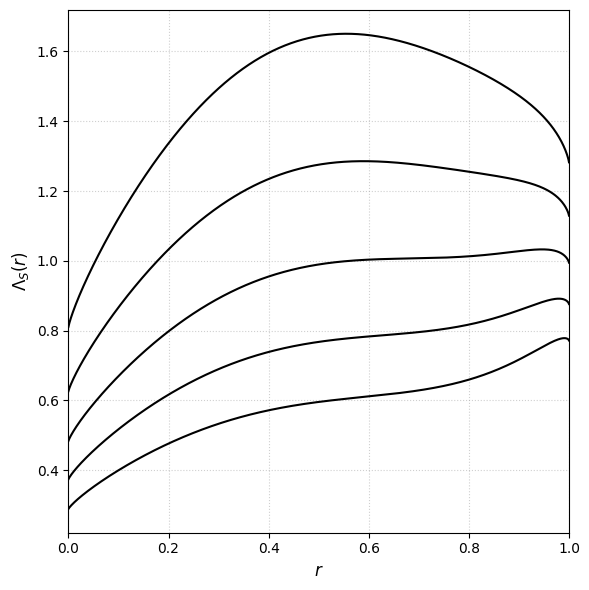

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters from your thesis
k = 5
eps = 1e-10
r = np.linspace(eps, 1-eps, 1000)
alphas = [14, 18, 22, 26, 30]

# Define the functions for standard SAT
def f_S(r_val):
    return 1 - 2**(1-k) + (2**(-k)) * (r_val**k)

def Lambda_S(r_val, alpha):
    denom = (r_val**r_val) * ((1-r_val)**(1-r_val))
    return (2 * (f_S(r_val)**alpha)) / denom

# Create the plot
plt.figure(figsize=(6, 6))

# Plot each alpha (from top to bottom, 14 to 30)
for alpha in alphas:
    plt.plot(r, Lambda_S(r, alpha), 'k-') # 'k-' makes the lines black

# Format the graph to match your other new plots
plt.xlabel('$r$', fontsize=12)
plt.ylabel(r'$\Lambda_S(r)$', fontsize=12)
plt.xlim(0, 1) # This ensures the x-axis strictly stops at 0 and 1
plt.grid(True, linestyle=':', alpha=0.6)

# Save the high-res image
plt.tight_layout()
plt.savefig('lambda_s_plot.png', dpi=300, bbox_inches='tight')
print("Plot successfully saved as 'lambda_s_plot.png'")